# Long-Scan Characterization — `longscan_dipoleON_10nC`

Applies the **`THz_Sensor_Characterization.ipynb`** reduction method to the
long-period delay scan `Data_raw/longscan_dipoleON_10nC.npz` (dipole ON, 10 nC nominal),
then computes the **THz spectrum (FFT)** of the recovered EO signal-vs-delay waveform.

Pipeline (identical constants/functions to the characterization notebook):
1. `phase → delay` conversion.
2. `reduce_bpd` — period-fill baseline subtraction + super-Gaussian FFT low-pass → signed EO amplitude vs delay.
3. `ict_charge` — per-shot ICT charge.
4. **FFT** of the signal-vs-delay waveform (Hanning window, mean-subtracted), per the group's spectral convention.

The delay axis is real time, so the EO signal-vs-delay *is* the time-domain THz waveform and its FFT is the THz spectrum.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, epsilon_0, e as q_e

# Anchor cwd at project root (run from Analysis/ or repo root)
if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')
os.makedirs('Results/longscan', exist_ok=True)
OUT = 'Results/longscan'

# ─── instrument constants (THz_Sensor_Characterization.ipynb) ───
RF_HZ       = 81.25e6
T_LASER_NS  = 1e9 / RF_HZ        # 12.31 ns laser period
MV          = 1e3                # V → mV

# BPD scope
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FFT_SIGMA_GHZ   = 0.35           # super-Gaussian LP cutoff (trace smoothing)
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25             # samples around the EO probe pulse

# ICT digitiser
ICT_BL_PRE  = slice(None, 700)
ICT_BL_POST = slice(1300, None)
DT_ICT_NS   = 0.444
ICT_K       = 0.8                # nC/(V·ns)

LONGSCAN_PATH = 'Data_raw/longscan_dipoleON_10nC.npz'
print('cwd =', os.getcwd())

cwd = /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26


## 1 · Load

In [2]:
d = np.load(LONGSCAN_PATH)
print('keys:', list(d.keys()))
t_ns     = 1e9 * d['x'][0, :]
BPDwf    = d['BPDwf']            # (steps, n_shots, 5000)
ictwf    = d['ictwf']           # (steps, n_shots, 2502)
phase    = d['phase']           # (steps,)

def delay_ps_from_phase(phase_deg):
    return (phase_deg - phase_deg[0]) / RF_HZ / 360 * 1e12

delay_ps = delay_ps_from_phase(phase)
dly_ns   = delay_ps / 1000

n_st, n_sh, n_sa = BPDwf.shape
print(f'steps={n_st}  shots/step={n_sh}  samples={n_sa}')
print(f'delay span = {np.ptp(delay_ps)/1000:.2f} ns  (laser period {T_LASER_NS:.2f} ns)')
print(f'delay step dt = {np.ptp(delay_ps)/(n_st-1):.3f} ps')

keys: ['x', 'BPDwf', 'ictwf', 'phase']
steps=3387  shots/step=4  samples=5000
delay span = 11.58 ns  (laser period 12.31 ns)
delay step dt = 3.419 ps


## 2 · BPD reduction — `reduce_bpd`

Verbatim from `THz_Sensor_Characterization.ipynb`. Baseline = the single clean
laser period just before the signal window, tiled across the window; residual is
super-Gaussian low-pass filtered. The probe time is the sample of maximum
variance across delay; the signed amplitude is the residual averaged over a
window around the probe.

In [3]:
def _period_fill_indices(t_ns, s0, s1):
    dt = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T  = T_LASER_NS / dt
    i0, i1 = int(round(s0/dt)), int(round(s1/dt))
    idx = np.arange(i0, i1)
    nl  = np.ceil((idx + 1 - i0) / T).astype(int)
    nr  = np.ceil((i1 - idx)       / T).astype(int)
    return i0, i1, np.round(idx - nl*T).astype(int), np.round(idx + nr*T).astype(int)

def fft_lowpass(arr, dt_ns):
    n = arr.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)
    H = np.exp(-0.5 * (freqs / FFT_SIGMA_GHZ) ** (2 * FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(arr, axis=1) * H, n=n, axis=1)

def reduce_bpd(t_ns, raw):
    n_st, n_sh, n_sa = raw.shape
    traces = raw.mean(axis=1)                                   # (steps, 5000)
    dt     = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    i0, i1, sl, sr = _period_fill_indices(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)
    bl = traces.copy()
    bl[:, i0:i1] = traces[:, sl]                                # pre-modulation period, tiled
    res = fft_lowpass(traces - bl, dt)
    tp  = int(res.var(axis=0).argmax())                         # probe time = max variance vs delay
    win = slice(max(0, tp - PROBE_HALF_WIN), min(res.shape[1], tp + PROBE_HALF_WIN))
    signed_amp = res[:, win].mean(axis=1)                       # (steps,)  V
    return dict(traces=traces, res=res, tp=tp, win=win, signed_amp=signed_amp, n_shots=n_sh)

b = reduce_bpd(t_ns, BPDwf)
amp = b['signed_amp']
imax = np.abs(amp).argmax()
print(f"probe time tp @ t = {t_ns[b['tp']]:.2f} ns  (sample {b['tp']})")
print(f"signed amp: min={MV*amp.min():.2f} mV  max={MV*amp.max():.2f} mV  "
      f"p2p={MV*np.ptp(amp):.2f} mV")
print(f"|amp|_max = {MV*np.abs(amp).max():.2f} mV  at delay = {dly_ns[imax]:.3f} ns")

probe time tp @ t = 53.18 ns  (sample 2659)
signed amp: min=-66.20 mV  max=53.71 mV  p2p=119.91 mV
|amp|_max = 66.20 mV  at delay = 7.764 ns


## 3 · ICT charge — `ict_charge`

In [4]:
def ict_charge(ict, min_Q_nC=0.0):
    bl = np.concatenate([ict[:, :, ICT_BL_PRE], ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)
    ictc = ict - bl[:, :, np.newaxis]
    raw_sum = -ictc.sum(axis=2)                                 # (steps, n_shots) V·samples
    Q_shot  = ICT_K * raw_sum * DT_ICT_NS                       # nC
    Q_kept  = np.where(Q_shot <= min_Q_nC, np.nan, Q_shot)
    return dict(per_shot=Q_shot, per_step=np.nanmean(Q_kept, axis=1),
                Q_mean=np.nanmean(Q_kept),
                dropout_frac=float((Q_shot <= min_Q_nC).mean()), ictc=ictc)

ict = ict_charge(ictwf, min_Q_nC=0.0)
print(f"Q_mean = {ict['Q_mean']:.3f} nC   dropout_frac = {100*ict['dropout_frac']:.1f}%")
print(f"per-step Q: min={np.nanmin(ict['per_step']):.2f}  max={np.nanmax(ict['per_step']):.2f} nC")

Q_mean = 10.048 nC   dropout_frac = 2.8%
per-step Q: min=3.33  max=11.69 nC


/tmp/ipykernel_76302/151083652.py:7: RuntimeWarning: Mean of empty slice
  return dict(per_shot=Q_shot, per_step=np.nanmean(Q_kept, axis=1),


## 4 · Time-domain: signal & charge vs delay

2071 2296


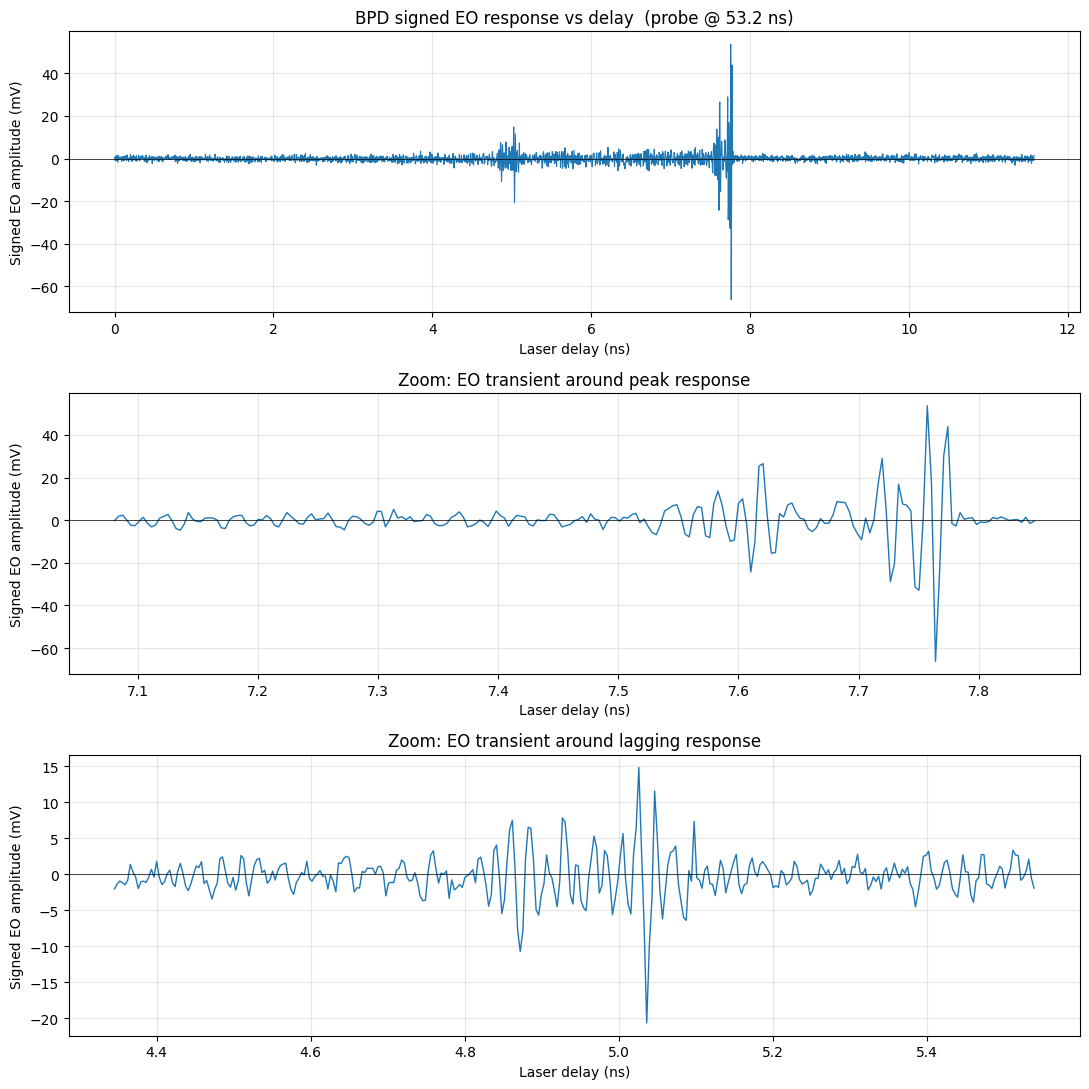

In [19]:
fig, ax = plt.subplots(3, 1, figsize=(11, 11))

ax[0].plot(dly_ns, MV*amp, lw=0.8, color='tab:blue')
ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_xlabel('Laser delay (ns)'); ax[0].set_ylabel('Signed EO amplitude (mV)')
ax[0].set_title(f"BPD signed EO response vs delay  (probe @ {t_ns[b['tp']]:.1f} ns)")
ax[0].grid(alpha=0.3)

lo, hi = max(0, imax-200), min(len(dly_ns), imax+25)
lo2, hi2 = max(0, imax-1000), min(len(dly_ns), imax-650)

print(lo, hi)
ax[1].plot(dly_ns[lo:hi], MV*amp[lo:hi], lw=1.0, color='tab:blue')
ax[1].axhline(0, color='k', lw=0.5)
ax[1].set_xlabel('Laser delay (ns)'); ax[1].set_ylabel('Signed EO amplitude (mV)')
ax[1].set_title('Zoom: EO transient around peak response'); ax[1].grid(alpha=0.3)

ax[2].plot(dly_ns[lo2:hi2], MV*amp[lo2:hi2], lw=1.0, color='tab:blue')
ax[2].axhline(0, color='k', lw=0.5)
ax[2].set_xlabel('Laser delay (ns)'); ax[2].set_ylabel('Signed EO amplitude (mV)')
ax[2].set_title('Zoom: EO transient around lagging response'); ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUT}/longscan_timedomain.png', dpi=160, bbox_inches='tight')
plt.show()

## 5 · FFT — THz spectrum of the signal-vs-delay waveform

Group convention (`Dipole_LongScan_Spectral.ipynb` / `Charge_Spectral_Analysis.ipynb`):
mean-subtract, apply a Hanning window, take `np.fft.rfft`, and convert the bin
axis to GHz with `rfftfreq(n, d=dt_ps·1e-12)`. The delay step sets the Nyquist
frequency and the record length sets the resolution Δf.

We FFT both (a) the **full-record** signal-vs-delay, and (b) a **windowed transient**
around the peak EO response, to separate the localized THz burst from the
slowly-varying long-period wake baseline.

In [6]:
def hann_fft(sig, dp):
    n     = len(sig)
    dt_ps = (dp[-1] - dp[0]) / (n - 1)
    w     = np.hanning(n)
    F     = np.abs(np.fft.rfft((sig - sig.mean()) * w))
    f     = np.fft.rfftfreq(n, d=dt_ps * 1e-12) / 1e9          # GHz
    return f, F, dt_ps

# (a) full record
f_full, F_full, dt_ps = hann_fft(amp, delay_ps)

# (b) windowed transient (±~1.4 ns around the peak EO response)
HALF = 400
lo, hi = max(0, imax-HALF), min(len(amp), imax+HALF)
f_tr, F_tr, _ = hann_fft(amp[lo:hi], delay_ps[lo:hi])

nyq = 0.5 / (dt_ps * 1e-3)
df  = 1.0 / (len(amp) * dt_ps * 1e-3)
print(f"N={len(amp)}  dt={dt_ps:.3f} ps  ->  Nyquist={nyq:.1f} GHz,  df={df:.3f} GHz")

def peak_centroid(f, F, fmin=2.0):
    m = f > fmin
    pk  = f[m][F[m].argmax()]
    cen = (f[m]*F[m]).sum() / F[m].sum()
    return pk, cen

pk_full, cen_full = peak_centroid(f_full, F_full)
pk_tr,   cen_tr   = peak_centroid(f_tr,   F_tr)
print(f"full record : peak={pk_full:6.2f} GHz   centroid={cen_full:6.2f} GHz")
print(f"transient   : peak={pk_tr:6.2f} GHz   centroid={cen_tr:6.2f} GHz")

N=3387  dt=3.419 ps  ->  Nyquist=146.2 GHz,  df=0.086 GHz
full record : peak= 58.03 GHz   centroid= 62.80 GHz
transient   : peak= 52.28 GHz   centroid= 64.14 GHz


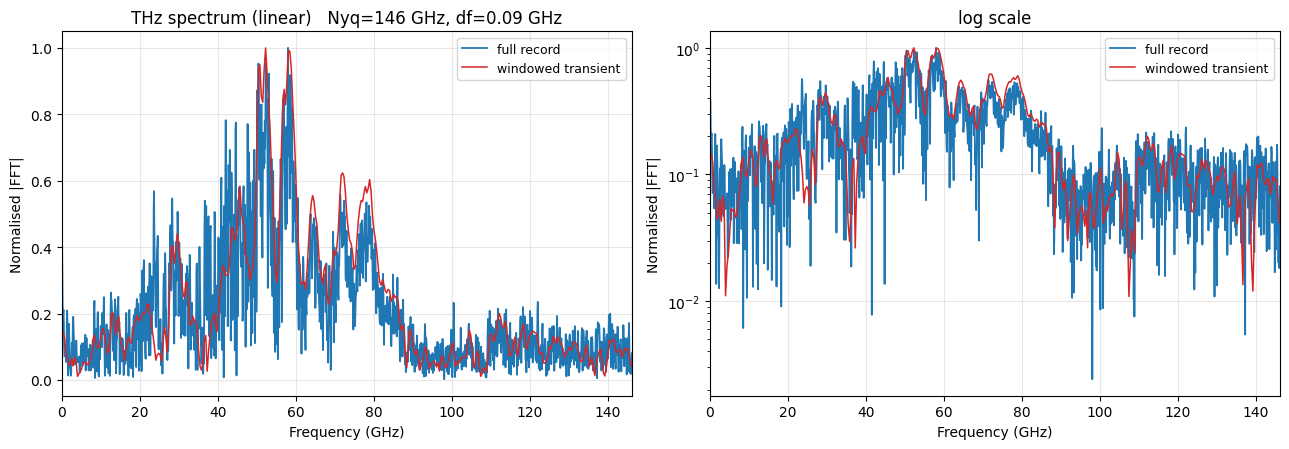

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, ylog in zip(axes, [False, True]):
    plot = ax.semilogy if ylog else ax.plot
    plot(f_full, F_full/F_full.max(), color='C0', lw=1.3, label='full record')
    plot(f_tr,   F_tr/F_tr.max(),     color='C3', lw=1.1, label='windowed transient')
    ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Normalised |FFT|')
    ax.set_xlim(0, min(150, nyq)); ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[0].set_title(f'THz spectrum (linear)   Nyq={nyq:.0f} GHz, df={df:.2f} GHz')
axes[1].set_title('log scale')
plt.tight_layout()
plt.savefig(f'{OUT}/longscan_fft.png', dpi=170, bbox_inches='tight')
plt.show()

## 6 · Summary

In [8]:
print('='*60)
print('Long-scan characterization — longscan_dipoleON_10nC.npz')
print('='*60)
print(f'steps / shots-per-step : {n_st} / {n_sh}')
print(f'delay span             : {np.ptp(delay_ps)/1000:.2f} ns')
print(f'probe time             : {t_ns[b["tp"]]:.2f} ns')
print(f'|EO amp|_max           : {MV*np.abs(amp).max():.2f} mV  @ delay {dly_ns[imax]:.3f} ns')
print(f'EO amp p2p             : {MV*np.ptp(amp):.2f} mV')
print(f'ICT mean charge        : {ict["Q_mean"]:.2f} nC  ({100*ict["dropout_frac"]:.1f}% dropouts)')
print(f'FFT Nyquist / df       : {nyq:.1f} GHz / {df:.3f} GHz')
print(f'spectral peak (transient): {pk_tr:.2f} GHz')
print(f'spectral centroid (transient): {cen_tr:.2f} GHz')

Long-scan characterization — longscan_dipoleON_10nC.npz
steps / shots-per-step : 3387 / 4
delay span             : 11.58 ns
probe time             : 53.18 ns
|EO amp|_max           : 66.20 mV  @ delay 7.764 ns
EO amp p2p             : 119.91 mV
ICT mean charge        : 10.05 nC  (2.8% dropouts)
FFT Nyquist / df       : 146.2 GHz / 0.086 GHz
spectral peak (transient): 52.28 GHz
spectral centroid (transient): 64.14 GHz
